# Retail & Warehouse Sales Analysis
### Exploratory Data Analysis, Product Performance and Business Recommendations

**Project objective:** Analyse retail sales, retail transfers and warehouse sales to identify product and supplier performance patterns, compare the available reporting months, and translate the findings into practical inventory and merchandising recommendations.

**Dataset:** `Retail and wherehouse Sale.csv`

> **Important scope note:** This dataset contains 30,000 records from 2020, but observations are present only for January, March, July and September.

## 1. Import libraries and load the dataset

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)
pd.set_option("display.max_columns", None)


file_path = "Retail and wherehouse Sale.csv"

df = pd.read_csv(file_path)


print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 30,000 rows × 9 columns


,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
0,2020,1,REPUBLIC NATIONAL DISTRIBUTING CO,100009,BOOTLEG RED - 750ML,WINE,0.00,0.0,2.0
1,2020,1,PWSWN INC,100024,MOMENT DE PLAISIR - 750ML,WINE,0.00,1.0,4.0
2,2020,1,RELIABLE CHURCHILL LLLP,1001,S SMITH ORGANIC PEAR CIDER - 18.7OZ,BEER,0.00,0.0,1.0
3,2020,1,LANTERNA DISTRIBUTORS INC,100145,SCHLINK HAUS KABINETT - 750ML,WINE,0.00,0.0,1.0
4,2020,1,DIONYSOS IMPORTS INC,100293,SANTORINI GAVALA WHITE - 750ML,WINE,0.82,0.0,0.0


## 2. Understand the data

In [8]:
print("Column names and data types")
display(pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(dropna=True)
}))

print("Duplicate rows:", df.duplicated().sum())
print("Reporting years:", sorted(df["YEAR"].dropna().unique().tolist()))
print("Months represented:", sorted(df["MONTH"].dropna().unique().tolist()))
print("Item types:", sorted(df["ITEM TYPE"].dropna().unique().tolist()))

Column names and data types


,Data Type,Missing Values,Missing (%),Unique Values
YEAR,int64,0,0.00,1
MONTH,int64,0,0.00,4
SUPPLIER,object,33,0.11,290
ITEM CODE,object,0,0.00,15668
ITEM DESCRIPTION,object,0,0.00,15732
ITEM TYPE,object,0,0.00,8
RETAIL SALES,float64,1,0.00,3657
RETAIL TRANSFERS,float64,0,0.00,542
WAREHOUSE SALES,float64,0,0.00,1032


Duplicate rows: 0
Reporting years: [2020]
Months represented: [1, 3, 7, 9]
Item types: ['BEER', 'DUNNAGE', 'KEGS', 'LIQUOR', 'NON-ALCOHOL', 'REF', 'STR_SUPPLIES', 'WINE']


### The main measures

- **RETAIL SALES:** recorded retail sales measure.
- **RETAIL TRANSFERS:** recorded transfers associated with retail operations.
- **WAREHOUSE SALES:** recorded warehouse sales measure.
- **ITEM CODE / ITEM DESCRIPTION:** identifiers used to analyse product-level performance.
- **SUPPLIER / ITEM TYPE:** supplier and product category fields.



## 3. Data quality checks and preparation

In [9]:
analysis_df = df.copy()

# Standardise text fields without changing the underlying meaning.
text_cols = ["SUPPLIER", "ITEM DESCRIPTION", "ITEM TYPE"]
for col in text_cols:
    analysis_df[col] = analysis_df[col].astype("string").str.strip()

# Keep missing supplier names visible as a separate group.
analysis_df["SUPPLIER"] = analysis_df["SUPPLIER"].fillna("Unknown Supplier")

# Investigate missing numeric values before choosing a treatment.
numeric_cols = ["RETAIL SALES", "RETAIL TRANSFERS", "WAREHOUSE SALES"]
print("Missing values in numeric measures:")
display(analysis_df[numeric_cols].isna().sum().to_frame("Missing Count"))

print("Rows with any negative numeric measure:")
negative_mask = (analysis_df[numeric_cols] < 0).any(axis=1)
print(f"{negative_mask.sum():,} rows ({negative_mask.mean():.2%})")

print("Negative values by measure:")
display((analysis_df[numeric_cols] < 0).sum().to_frame("Negative Count"))

# For calculations that require retail sales, exclude only the single row
# with missing RETAIL SALES. Keep the full prepared dataset for other measures.
sales_df = analysis_df.dropna(subset=["RETAIL SALES"]).copy()
print(f"Rows available for retail-sales analysis: {len(sales_df):,}")

Missing values in numeric measures:


,Missing Count
RETAIL SALES,1
RETAIL TRANSFERS,0
WAREHOUSE SALES,0


Rows with any negative numeric measure:
98 rows (0.33%)
Negative values by measure:


,Negative Count
RETAIL SALES,6
RETAIL TRANSFERS,16
WAREHOUSE SALES,76


Rows available for retail-sales analysis: 29,999


### Data-cleaning decisions

- Missing supplier names are labelled **Unknown Supplier** so those records are not silently lost.
- The one missing **RETAIL SALES** value is excluded only from analyses that require that measure; it is not replaced with an invented value.
- Negative values are retained for investigation. They may represent returns, corrections or adjustments, but the dataset does not explain their meaning. Confirm with the data owner before removing or changing them.
- Duplicate rows are reported above but are not automatically deleted: identical-looking records may be valid repeated observations.

## 4. Descriptive statistics and distribution

,count,mean,std,min,25%,50%,75%,max
RETAIL SALES,29999.0,6.94,33.08,-0.42,0.0,0.16,2.92,2739.0
RETAIL TRANSFERS,29999.0,6.59,27.88,-6.00,0.0,0.00,3.00,1507.0
WAREHOUSE SALES,29999.0,27.43,272.17,-3999.00,0.0,1.00,6.00,18317.0


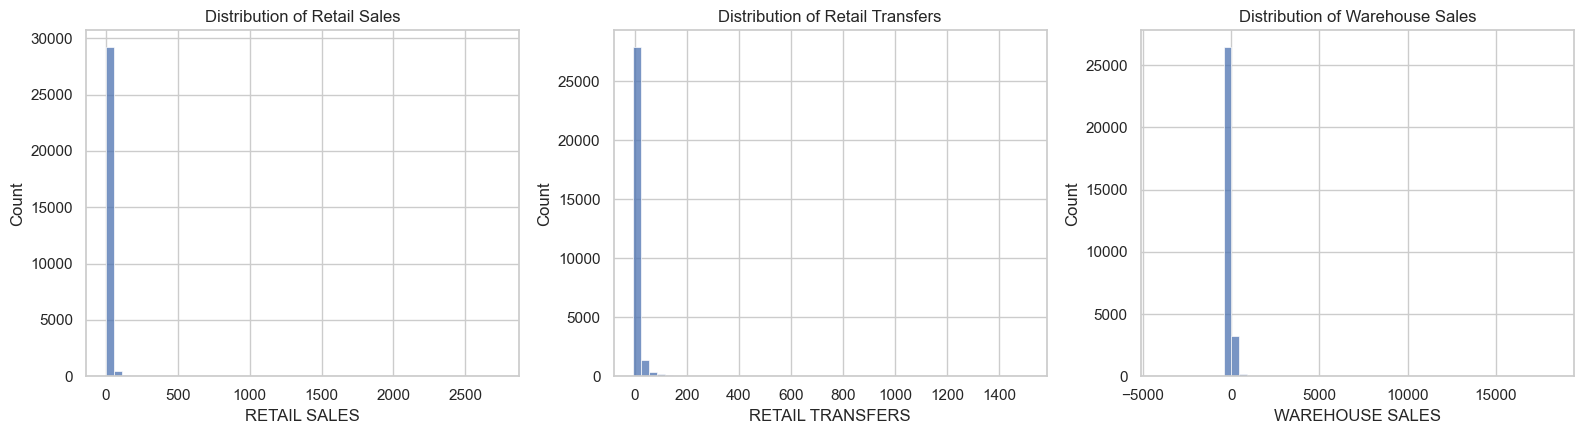

In [10]:
display(sales_df[numeric_cols].describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=sales_df, x=col, bins=50, ax=ax)
    ax.set_title(f"Distribution of {col.title()}")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

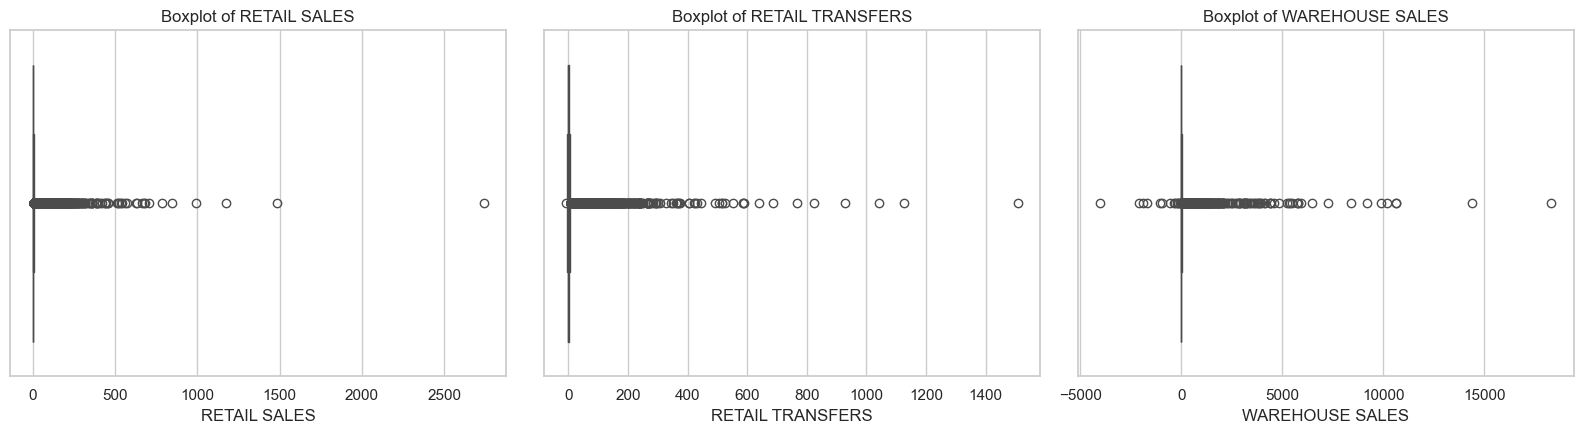

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(
        x=sales_df[col],
        ax=ax
    )

    ax.set_title(f"Boxplot of {col}")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

**Interpretation:** The histograms and boxplots show that Retail Sales, Retail Transfers, and Warehouse Sales are strongly right-skewed, with most observations concentrated at relatively low values and a few extreme values. Warehouse Sales exhibits the greatest variability. Negative values are also present and require further investigation. Potential outliers should be validated before deciding whether to remove or retain them

## 5. Reporting-month comparison

,Records,Products,Retail_Sales,Retail_Transfers,Warehouse_Sales
MONTH,,,,,
1,11987,11987,74318.77,75997.35,284114.72
3,5730,5730,34523.90,34505.08,113305.22
7,11189,11189,94538.96,82706.57,418094.42
9,1093,1093,4805.31,4612.74,7416.57


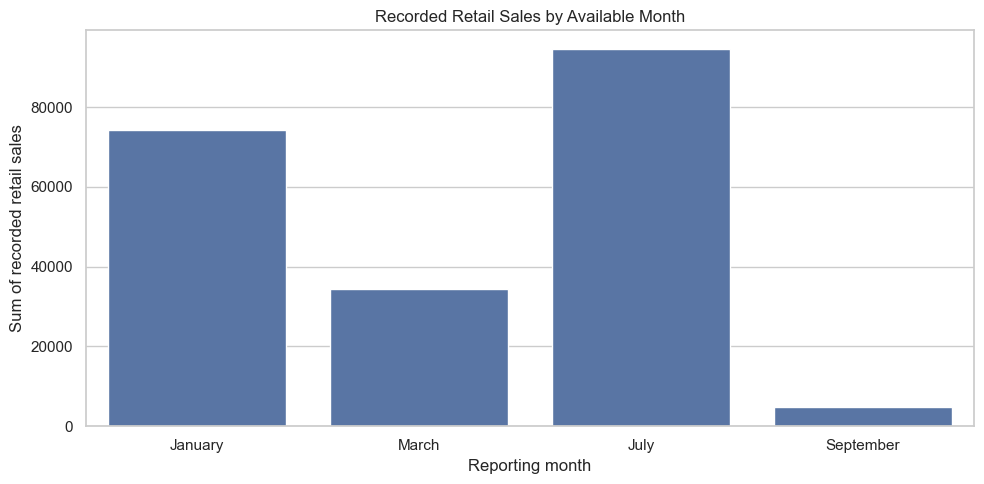

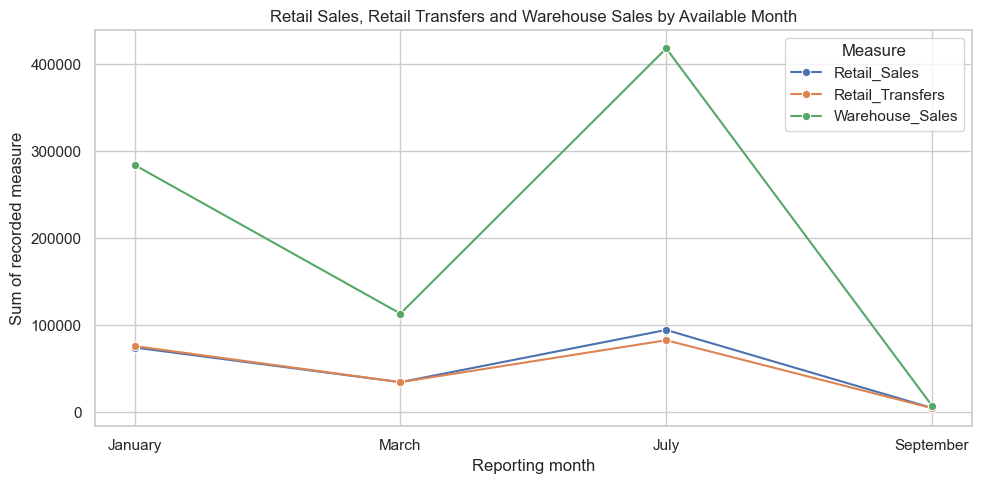

In [12]:
month_summary = (
    sales_df.groupby("MONTH")
    .agg(
        Records=("ITEM CODE", "size"),
        Products=("ITEM CODE", "nunique"),
        Retail_Sales=("RETAIL SALES", "sum"),
        Retail_Transfers=("RETAIL TRANSFERS", "sum"),
        Warehouse_Sales=("WAREHOUSE SALES", "sum")
    )
    .sort_index()
)
display(month_summary.round(2))

month_labels = {1:"January", 2:"February", 3:"March", 4:"April", 5:"May", 6:"June",
                7:"July", 8:"August", 9:"September", 10:"October", 11:"November", 12:"December"}
plot_month = month_summary.reset_index()
plot_month["Month Name"] = plot_month["MONTH"].map(month_labels)

plt.figure(figsize=(10, 5))
sns.barplot(data=plot_month, x="Month Name", y="Retail_Sales")
plt.title("Recorded Retail Sales by Available Month")
plt.xlabel("Reporting month")
plt.ylabel("Sum of recorded retail sales")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
month_long = plot_month.melt(
    id_vars="Month Name",
    value_vars=["Retail_Sales", "Retail_Transfers", "Warehouse_Sales"],
    var_name="Measure", value_name="Recorded Value"
)
sns.lineplot(data=month_long, x="Month Name", y="Recorded Value", hue="Measure", marker="o")
plt.title("Retail Sales, Retail Transfers and Warehouse Sales by Available Month")
plt.xlabel("Reporting month")
plt.ylabel("Sum of recorded measure")
plt.tight_layout()
plt.show()

### Monthly analysis

The file contains January, March, July and September only.The chart compares retail sales, retail transfers, and warehouse sales across the available months.

## 6. Product-category performance

,Records,Unique_Products,Retail_Sales,Retail_Transfers,Warehouse_Sales,Retail Sales Share (%)
ITEM TYPE,,,,,,
LIQUOR,5995,2854,81742.85,79599.70,8796.90,39.26
WINE,18680,9815,59688.84,58629.13,119459.93,28.67
BEER,4217,2330,59538.76,55729.83,697279.68,28.60
NON-ALCOHOL,215,103,6824.62,2934.08,2438.42,3.28
STR_SUPPLIES,63,25,345.60,895.00,0.00,0.17
REF,8,4,46.27,34.00,-1329.00,0.02
DUNNAGE,13,4,0.00,0.00,-12115.00,0.00
KEGS,808,532,0.00,0.00,8400.00,0.00


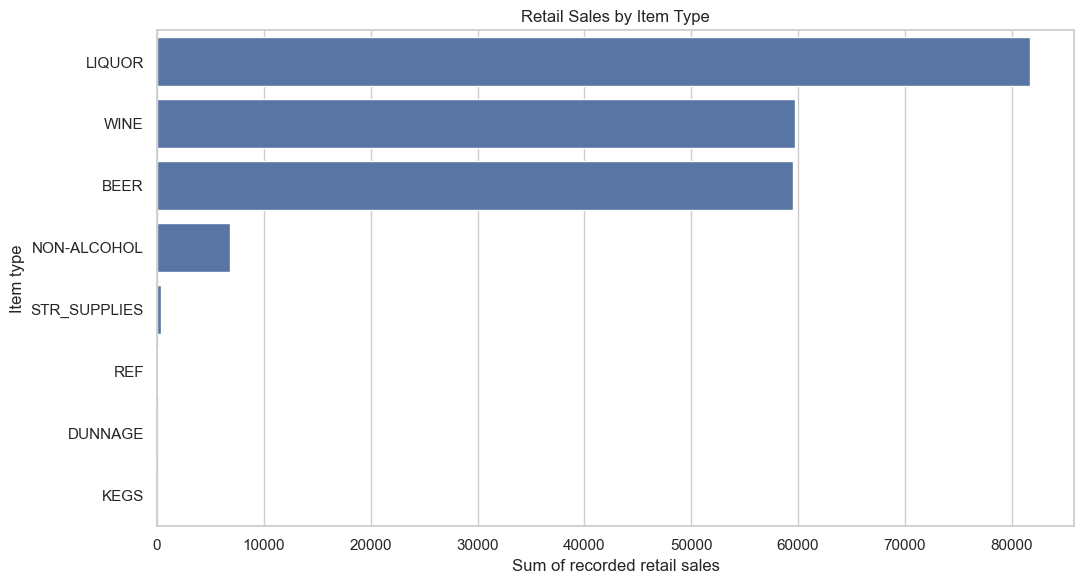

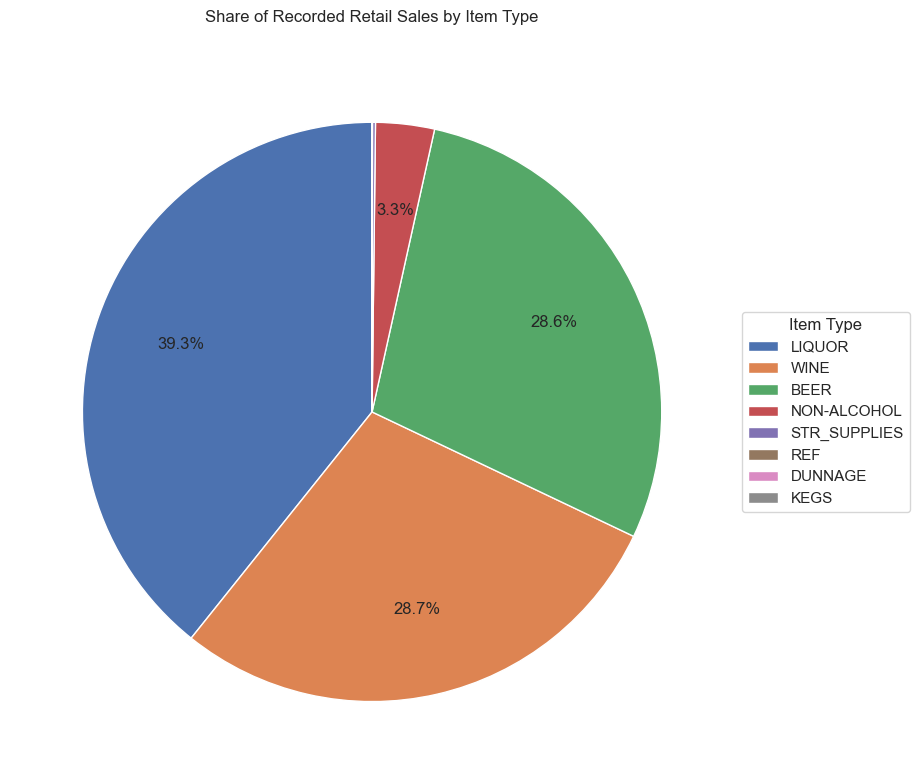

In [13]:
type_summary = (
    sales_df.groupby("ITEM TYPE")
    .agg(
        Records=("ITEM CODE", "size"),
        Unique_Products=("ITEM CODE", "nunique"),
        Retail_Sales=("RETAIL SALES", "sum"),
        Retail_Transfers=("RETAIL TRANSFERS", "sum"),
        Warehouse_Sales=("WAREHOUSE SALES", "sum")
    )
    .sort_values("Retail_Sales", ascending=False)
)
type_summary["Retail Sales Share (%)"] = (
    type_summary["Retail_Sales"] / type_summary["Retail_Sales"].sum() * 100
)
display(type_summary.round(2))

plt.figure(figsize=(11, 6))
sns.barplot(data=type_summary.reset_index(), x="Retail_Sales", y="ITEM TYPE")
plt.title("Retail Sales by Item Type")
plt.xlabel("Sum of recorded retail sales")
plt.ylabel("Item type")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))

type_share = type_summary["Retail Sales Share (%)"].sort_values(
    ascending=False
)

plt.pie(
    type_share,
    labels=None,  # Avoid overlapping labels
    autopct=lambda p: f"{p:.1f}%" if p >= 2 else "",
    startangle=90,
    pctdistance=0.7,
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)

plt.legend(
    type_share.index,
    title="Item Type",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Share of Recorded Retail Sales by Item Type", pad=20)
plt.tight_layout()
plt.show()

**Business use:** categories with a large share of recorded retail sales may deserve closer attention in replenishment and assortment reviews. Pair total sales with the number of distinct products and warehouse measures before deciding how much inventory to allocate; a high total alone does not prove higher profitability or faster stock turnover.

## 7. Supplier performance

Top 10 suppliers by recorded retail sales


,Records,Unique_Products,Retail_Sales,Retail_Transfers,Warehouse_Sales
SUPPLIER,,,,,
DIAGEO NORTH AMERICA INC,662,310,13840.54,13245.98,20807.36
E & J GALLO WINERY,898,454,12742.24,11970.41,17734.00
ANHEUSER BUSCH INC,556,258,10091.64,9344.50,137538.52
CONSTELLATION BRANDS,640,277,9931.78,9467.82,11193.01
JIM BEAM BRANDS CO,528,243,9845.79,9640.19,757.76
CROWN IMPORTS,135,61,9341.80,8899.00,183092.82
SAZERAC CO,486,251,7739.14,7169.17,1958.25
MILLER BREWING COMPANY,306,144,7737.55,6888.50,125280.03
BACARDI USA INC,303,143,6121.70,5821.75,735.75


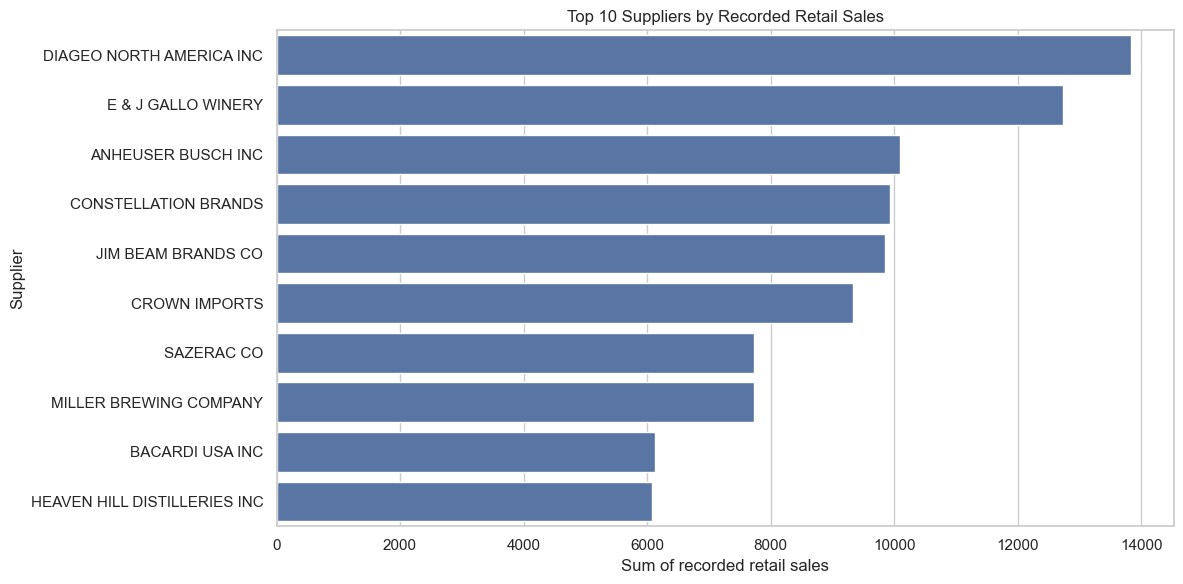

Suppliers with the lowest recorded retail-sales totals (including possible negative totals)


,Records,Unique_Products,Retail_Sales,Retail_Transfers,Warehouse_Sales
SUPPLIER,,,,,
GJS SALES INC,1,1,0.0,0.0,25.0
TAPWINES,16,14,0.0,0.0,29.0
KAHN PAPER COMPANY INC,9,5,0.0,526.0,0.0
IMPERO WINE DISTRIBUTORS,25,19,0.0,0.0,111.0
HOUTON PURVEYORS LLC,7,6,0.0,0.0,20.0
HARVEST IMPORTING LLC,15,11,0.0,0.0,30.0
HAMCO DC,2,1,0.0,56.0,0.0
THE WINE SOURCE INC,10,10,0.0,0.0,52.0
GOOSE RIDGE LLC,15,9,0.0,0.0,44.0


In [14]:
supplier_summary = (
    sales_df.groupby("SUPPLIER")
    .agg(
        Records=("ITEM CODE", "size"),
        Unique_Products=("ITEM CODE", "nunique"),
        Retail_Sales=("RETAIL SALES", "sum"),
        Retail_Transfers=("RETAIL TRANSFERS", "sum"),
        Warehouse_Sales=("WAREHOUSE SALES", "sum")
    )
    .sort_values("Retail_Sales", ascending=False)
)

print("Top 10 suppliers by recorded retail sales")
display(supplier_summary.head(10).round(2))

top_suppliers = supplier_summary.head(10).reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(data=top_suppliers, x="Retail_Sales", y="SUPPLIER")
plt.title("Top 10 Suppliers by Recorded Retail Sales")
plt.xlabel("Sum of recorded retail sales")
plt.ylabel("Supplier")
plt.tight_layout()
plt.show()

print("Suppliers with the lowest recorded retail-sales totals (including possible negative totals)")
display(supplier_summary.tail(10).sort_values("Retail_Sales").round(2))

**Interpretation:** supplier totals are useful for identifying where recorded sales are concentrated. They are not a complete supplier scorecard: purchasing cost, delivery reliability, lead time, stock-outs, returns and contractual terms are not present in this file. The “Unknown Supplier” group should be reviewed separately.

## 8. Top products

Top 15 products by recorded retail sales


,,,Retail_Sales,Retail_Transfers,Warehouse_Sales,Records
ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,,,,
2,ICE,NON-ALCOHOL,3842.00,0.00,0.00,3
23445,CORONA EXTRA LOOSE NR - 12OZ,BEER,2845.00,2934.00,43330.50,3
53929,TITO'S HANDMADE VODKA - 1.75L,LIQUOR,2330.99,2436.17,48.00,2
23886,HEINEKEN LOOSE NR - 12OZ,BEER,2096.00,2097.00,22599.88,3
26187,STELLA ARTOIS LOOSE NR - 11.2OZ,BEER,1348.00,1332.00,4243.00,3
23905,MILLER LITE HIGH GRAPHIC LOOSE NR - 12OZ,BEER,1258.00,1184.00,2344.00,3
96750,CORONA EXTRA 2/12 NR - 12OZ,BEER,1105.00,961.00,19016.50,2
90590,MILLER LITE 30PK CAN - 12OZ,BEER,1045.00,766.00,11648.40,2
2810,YUENGLING LAGER LOOSE NR - 12OZ,BEER,961.00,956.00,921.00,3


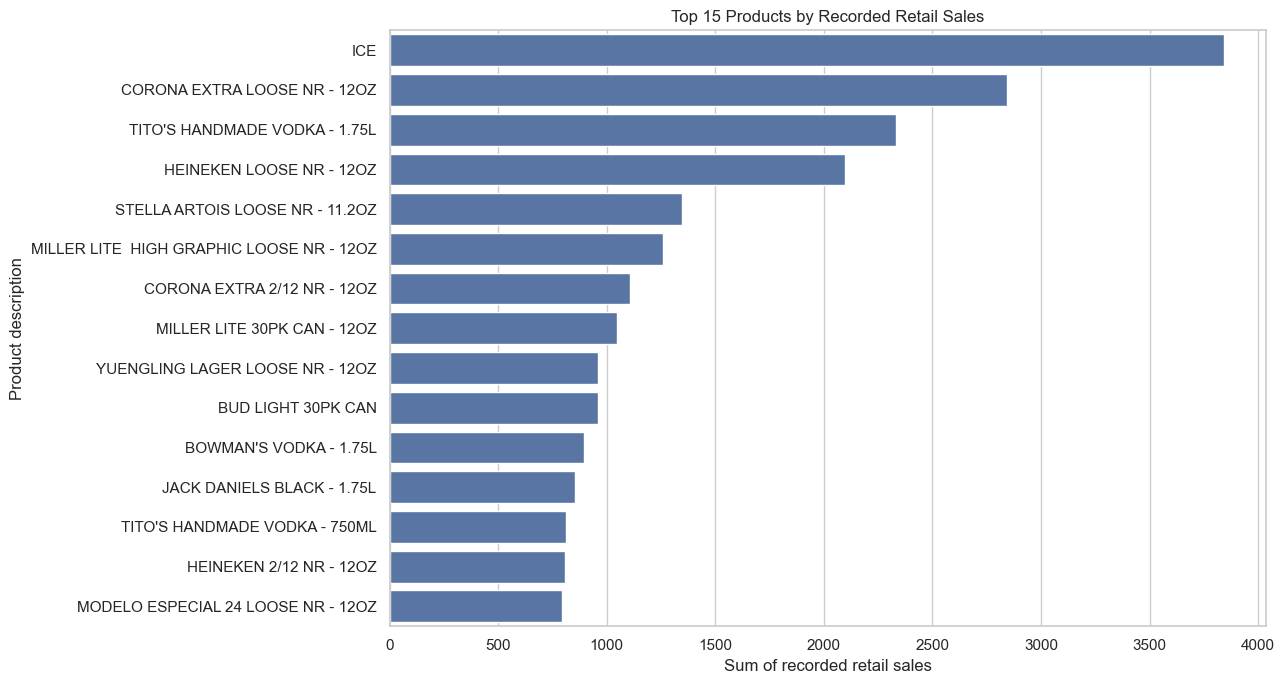

In [15]:
product_summary = (
    sales_df.groupby(["ITEM CODE", "ITEM DESCRIPTION", "ITEM TYPE"], dropna=False)
    .agg(
        Retail_Sales=("RETAIL SALES", "sum"),
        Retail_Transfers=("RETAIL TRANSFERS", "sum"),
        Warehouse_Sales=("WAREHOUSE SALES", "sum"),
        Records=("ITEM CODE", "size")
    )
    .sort_values("Retail_Sales", ascending=False)
)

print("Top 15 products by recorded retail sales")
display(product_summary.head(15).round(2))

top_products = product_summary.head(15).reset_index()
plt.figure(figsize=(13, 7))
sns.barplot(data=top_products, x="Retail_Sales", y="ITEM DESCRIPTION")
plt.title("Top 15 Products by Recorded Retail Sales")
plt.xlabel("Sum of recorded retail sales")
plt.ylabel("Product description")
plt.tight_layout()
plt.show()

## 9. Retail sales compared with warehouse sales and transfers

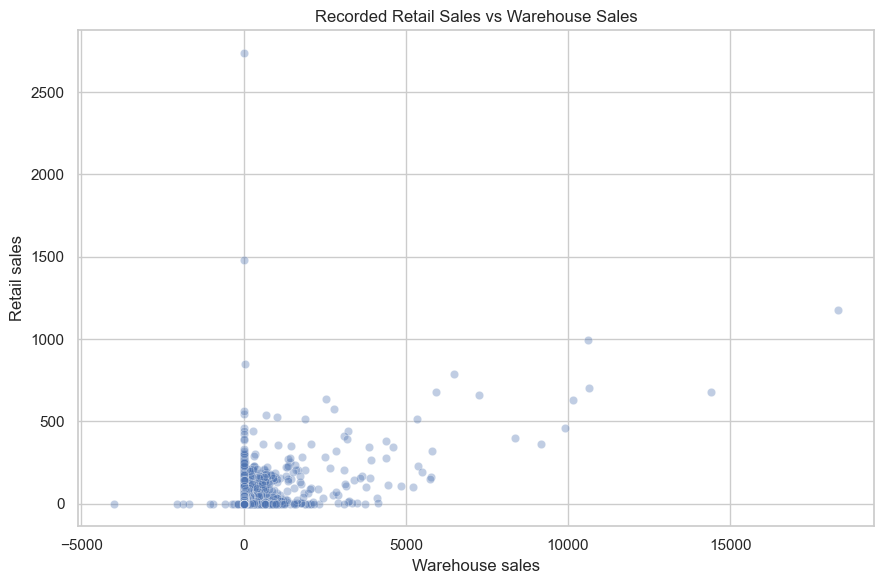

Correlation matrix for recorded numeric measures


,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
RETAIL SALES,1.000,0.845,0.492
RETAIL TRANSFERS,0.845,1.000,0.540
WAREHOUSE SALES,0.492,0.540,1.000


In [16]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=sales_df,
    x="WAREHOUSE SALES",
    y="RETAIL SALES",
    alpha=0.35
)
plt.title("Recorded Retail Sales vs Warehouse Sales")
plt.xlabel("Warehouse sales")
plt.ylabel("Retail sales")
plt.tight_layout()
plt.show()

print("Correlation matrix for recorded numeric measures")
display(sales_df[numeric_cols].corr().round(3))

**Interpretation**: The correlation analysis reveals a strong positive relationship between Retail Sales and Retail Transfers (0.845), while Warehouse Sales has moderate positive correlations with Retail Sales (0.492) and Retail Transfers (0.540). These findings indicate that higher recorded values tend to be associated across these variables. However, correlation does not imply causation, and extreme observations or differences in how the measures are defined may influence the results.

## 10. Product sales segmentation

,Products,Total_Retail_Sales,Average_Retail_Sales,Median_Retail_Sales
Sales Segment,,,,
Higher-sales half,15663,208187.37,13.21,0.00
Lower-sales half,4,-0.43,-0.11,-0.12


,Sales Segment,ITEM TYPE,Products,Retail_Sales
3,Higher-sales half,LIQUOR,2852,81743.03
7,Higher-sales half,WINE,9814,59689.01
0,Higher-sales half,BEER,2330,59538.76
4,Higher-sales half,NON-ALCOHOL,103,6824.62
6,Higher-sales half,STR_SUPPLIES,25,345.60
5,Higher-sales half,REF,3,46.35
1,Higher-sales half,DUNNAGE,4,0.00
2,Higher-sales half,KEGS,532,0.00
9,Lower-sales half,REF,1,-0.08
10,Lower-sales half,WINE,1,-0.17


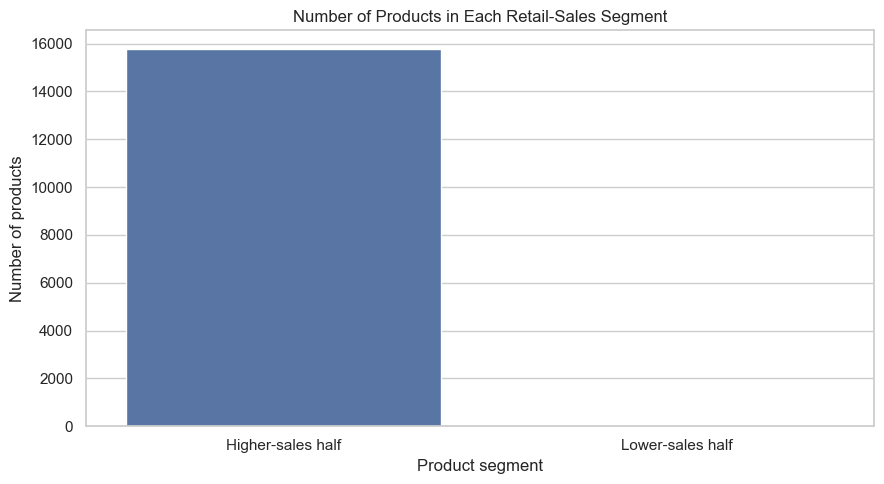

In [17]:
# Segment products using their aggregate retail-sales total.
# This is a descriptive ranking tool, not a prediction model.
product_level = product_summary.reset_index().copy()
median_product_sales = product_level["Retail_Sales"].median()
product_level["Sales Segment"] = np.where(
    product_level["Retail_Sales"] >= median_product_sales,
    "Higher-sales half",
    "Lower-sales half"
)

segment_summary = (
    product_level.groupby("Sales Segment", observed=False)
    .agg(
        Products=("ITEM CODE", "nunique"),
        Total_Retail_Sales=("Retail_Sales", "sum"),
        Average_Retail_Sales=("Retail_Sales", "mean"),
        Median_Retail_Sales=("Retail_Sales", "median")
    )
)
display(segment_summary.round(2))

segment_type = (
    product_level.groupby(["Sales Segment", "ITEM TYPE"], observed=False)
    .agg(Products=("ITEM CODE", "nunique"), Retail_Sales=("Retail_Sales", "sum"))
    .reset_index()
)
display(segment_type.sort_values(["Sales Segment", "Retail_Sales"], ascending=[True, False]).round(2))

plt.figure(figsize=(9, 5))
sns.countplot(data=product_level, x="Sales Segment")
plt.title("Number of Products in Each Retail-Sales Segment")
plt.xlabel("Product segment")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()

### How to use the segmentation

- **Higher-sales half:** prioritise for closer stock monitoring and review of replenishment settings.
- **Lower-sales half:** review product availability, assortment role and whether sales are intermittent.
- Use item type and warehouse/transfer measures as additional context before making inventory changes.

The split is based on the median product-level total in this dataset.

## 11. Key findings generated from the data

In [18]:
# Calculate a few factual summaries from the current dataset.
month_totals = sales_df.groupby("MONTH")["RETAIL SALES"].sum().sort_values(ascending=False)
type_totals = sales_df.groupby("ITEM TYPE")["RETAIL SALES"].sum().sort_values(ascending=False)
supplier_totals = sales_df.groupby("SUPPLIER")["RETAIL SALES"].sum().sort_values(ascending=False)
product_totals = sales_df.groupby(["ITEM CODE", "ITEM DESCRIPTION"])["RETAIL SALES"].sum().sort_values(ascending=False)

print(f"Records in original dataset: {len(df):,}")
print(f"Records with non-missing retail sales: {len(sales_df):,}")
print(f"Missing supplier names in original data: {df['SUPPLIER'].isna().sum():,}")
print(f"Months represented: {', '.join(month_labels.get(int(m), str(m)) for m in sorted(df['MONTH'].unique()))}")

if len(month_totals):
    print(f"Month with highest recorded retail-sales total among observed months: {month_labels.get(int(month_totals.index[0]), month_totals.index[0])} ({month_totals.iloc[0]:,.2f})")
if len(type_totals):
    print(f"Item type with highest recorded retail-sales total: {type_totals.index[0]} ({type_totals.iloc[0]:,.2f})")
if len(supplier_totals):
    print(f"Supplier with highest recorded retail-sales total: {supplier_totals.index[0]} ({supplier_totals.iloc[0]:,.2f})")
if len(product_totals):
    print(f"Top product by recorded retail-sales total: {product_totals.index[0][1]} ({product_totals.iloc[0]:,.2f})")

Records in original dataset: 30,000
Records with non-missing retail sales: 29,999
Missing supplier names in original data: 33
Months represented: January, March, July, September
Month with highest recorded retail-sales total among observed months: July (94,538.96)
Item type with highest recorded retail-sales total: LIQUOR (81,742.85)
Supplier with highest recorded retail-sales total: DIAGEO NORTH AMERICA INC (13,840.54)
Top product by recorded retail-sales total: ICE (3,842.00)


## 13. Conclusion

This project presents a comprehensive analysis of retail and warehouse sales data to identify patterns, evaluate product-category performance, and understand the relationships between key business variables. Through data cleaning, descriptive statistics, visualisations, and correlation analysis, the study provides insights into sales distribution, product performance, and operational activity.

The analysis reveals that sales and transfer values are strongly right-skewed, with most observations concentrated at relatively low values and a small number of extreme observations. Product-category analysis highlights differences in the contribution of individual categories to recorded retail sales. Correlation analysis identifies a strong positive relationship between Retail Sales and Retail Transfers (0.845), while Warehouse Sales has moderate positive relationships with Retail Sales (0.492) and Retail Transfers (0.540).

These findings can help businesses identify important product categories, investigate unusual transactions, and better understand the relationship between retail activity and warehouse operations. However, extreme and negative values require further validation before operational decisions are made.

Overall, the project demonstrates how exploratory data analysis can transform raw transactional data into meaningful business insights.